<a href="https://colab.research.google.com/github/Dimas-091206/Proyek-Akhir-Kelompok-9-Online-Retail-II/blob/main/Varian_1_Kelompok_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Proyek Akhir Pembelajaran Mesin: Klasifikasi Negara Pelanggan (UK vs non-UK)
## Anggota 1 (Varian Dasar): k-NN dengan k = 5

**Dataset:** Online Retail II (data pelanggan hasil agregasi, sudah bersih)
**Target:** `kelompok_negara` (UK / non-UK)
**Fitur (6):** recency, frekuensi, total_belanja, produk_unik, total_item, n_faktur_batal

**Tugas:** membangun k-NN (k = 5) pada enam fitur yang sudah diskalakan, menilai hasilnya
lewat confusion matrix, dan membandingkannya dengan garis dasar 91,15%.


## Langkah 1. Impor pustaka


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay, classification_report,
    accuracy_score, precision_score, recall_score, f1_score, balanced_accuracy_score
)

RANDOM_STATE = 42

## Langkah 2. Mengambil dataset dari Google Drive

Cara menyiapkan (cukup sekali):
1. Upload `data_bersih_pelanggan.csv` ke Google Drive.
2. Klik kanan file → **Bagikan / Share** → ubah akses menjadi **"Siapa saja yang memiliki link"** (Viewer).
3. Salin link-nya. Bentuknya `https://drive.google.com/file/d/XXXXXXXX/view?usp=sharing`.
4. Ambil bagian `XXXXXXXX` (itu **FILE_ID**) dan tempel di sel di bawah.

Setelah itu notebook bisa dijalankan ulang tanpa upload manual.

In [ ]:
import gdown

FILE_ID = "1ce3K3K2Vet0XDI7uSp6A44pUXnJC3BpW"   # <-- ganti dengan FILE_ID milikmu
OUTPUT  = "data_bersih_pelanggan.csv"

gdown.download(id=FILE_ID, output=OUTPUT, quiet=False)

df = pd.read_csv(OUTPUT)
print("Ukuran data:", df.shape)
df.head()

Downloading...
From: https://drive.google.com/uc?id=1ce3K3K2Vet0XDI7uSp6A44pUXnJC3BpW
To: /content/data_bersih_pelanggan.csv
100%|██████████| 481k/481k [00:00<00:00, 35.2MB/s]


Ukuran data: (5852, 14)


,Customer ID,total_belanja,frekuensi,recency,tenure_hari,produk_unik,total_item,n_faktur_batal,rata_nilai_faktur,nilai_batal,total_belanja_bersih,negara,n_negara,kelompok_negara
0,12346,77352.96,3,325,647,25,74239,1.0,25784.32000,-77183.60,169.36,United Kingdom,1,UK
1,12347,4921.53,8,2,404,126,2967,0.0,615.19125,0.00,4921.53,Iceland,1,non-UK
2,12348,1658.40,5,75,438,24,2704,0.0,331.68000,0.00,1658.40,Finland,1,non-UK
3,12349,3678.69,3,18,589,137,1621,1.0,1226.23000,-24.15,3654.54,Italy,1,non-UK
4,12350,294.40,1,310,310,16,196,0.0,294.40000,0.00,294.40,Norway,1,non-UK


**Alternatif** jika `gdown` gagal (misalnya kuota unduhan Drive terlampaui): mount Drive langsung,
lalu ganti `read_csv` dengan path file-nya. Jalankan sel di bawah hanya bila diperlukan.


In [ ]:
# from google.colab import drive
# drive.mount('/content/drive')
# df = pd.read_csv('/content/drive/MyDrive/NAMA_FOLDER/data_bersih_pelanggan.csv')

## Langkah 3. Memeriksa data dan garis dasar (baseline)

Garis dasar adalah akurasi model "bodoh" yang selalu menebak kelas mayoritas (UK).
Model k-NN baru dianggap berguna kalau mengalahkan angka ini.

Nilai kosong total : 0
Baris duplikat     : 0

                 jumlah  persen
kelompok_negara                
UK                 5334   91.15
non-UK              518    8.85

Garis dasar (tebak selalu UK) = 91.15%


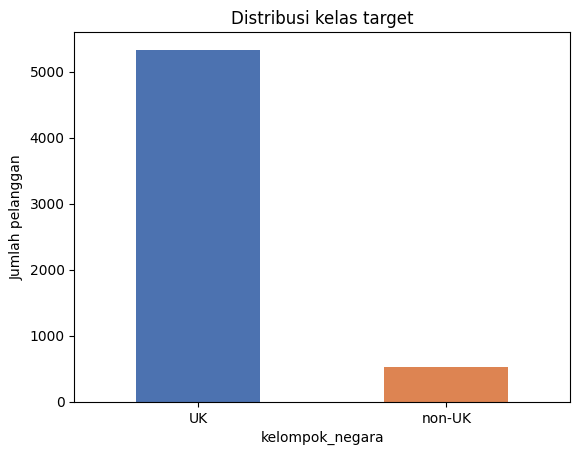

In [ ]:
print("Nilai kosong total :", df.isnull().sum().sum())
print("Baris duplikat     :", df.duplicated().sum())
print()

dist = df["kelompok_negara"].value_counts()
dist_pct = df["kelompok_negara"].value_counts(normalize=True) * 100
print(pd.DataFrame({"jumlah": dist, "persen": dist_pct.round(2)}))

BASELINE = dist_pct["UK"]
print(f"\nGaris dasar (tebak selalu UK) = {BASELINE:.2f}%")

dist.plot(kind="bar", color=["#4C72B0", "#DD8452"])
plt.title("Distribusi kelas target")
plt.ylabel("Jumlah pelanggan")
plt.xticks(rotation=0)
plt.show()

## Langkah 4. Memilih fitur dan target

Enam fitur sesuai proposal (Bagian C). Kolom `negara` dan `n_negara` **tidak dipakai** karena
keduanya menyusun target (kebocoran data / *data leakage*). `Customer ID` hanya pengenal.

Target diubah ke angka: **UK = 0, non-UK = 1**. Kelas **non-UK dijadikan kelas positif** karena
kelas minoritas inilah yang sulit dikenali, sehingga recall dan precision bermakna untuknya.

In [ ]:
FITUR = ["recency", "frekuensi", "total_belanja",
         "produk_unik", "total_item", "n_faktur_batal"]

X = df[FITUR]
y = (df["kelompok_negara"] == "non-UK").astype(int)   # UK=0, non-UK=1

print("Bentuk X:", X.shape, "| Bentuk y:", y.shape)
X.describe().T.round(2)

Bentuk X: (5852, 6) | Bentuk y: (5852,)


,count,mean,std,min,25%,50%,75%,max
recency,5852.0,199.73,208.52,0.00,25.00,95.00,379.00,738.00
frekuensi,5852.0,6.25,12.75,1.00,1.00,3.00,7.00,373.00
total_belanja,5852.0,2916.71,14306.87,2.95,339.58,856.02,2241.03,580987.04
produk_unik,5852.0,82.19,116.50,1.00,19.00,45.00,103.00,2546.00
total_item,5852.0,1794.04,8890.84,1.00,189.00,484.50,1352.50,367072.00
n_faktur_batal,5852.0,1.24,3.33,0.00,0.00,0.00,1.00,93.00


## Langkah 5. Membagi data latih dan data uji (berstrata)

Data dibagi **80% latih : 20% uji** dengan `stratify=y` agar proporsi UK/non-UK di kedua bagian
sama dengan data asli (kelas sangat timpang).

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

print("Data latih:", X_train.shape, "| Data uji:", X_test.shape)
print("\nProporsi non-UK di data latih: {:.2f}%".format(y_train.mean() * 100))
print("Proporsi non-UK di data uji  : {:.2f}%".format(y_test.mean() * 100))

Data latih: (4681, 6) | Data uji: (1171, 6)

Proporsi non-UK di data latih: 8.84%
Proporsi non-UK di data uji  : 8.88%


## Langkah 6. Penskalaan fitur (StandardScaler)

k-NN bekerja dengan jarak, jadi fitur berskala besar (misalnya `total_item`, yang bisa ratusan
ribu) akan mendominasi fitur berskala kecil (`n_faktur_batal`) bila tidak diskalakan.

**Penting:** scaler hanya di-*fit* pada data latih, lalu dipakai untuk mentransformasi data uji.
Kalau di-*fit* pada seluruh data, informasi data uji bocor ke proses latih.

In [ ]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)   # fit hanya di data latih
X_test_s  = scaler.transform(X_test)        # data uji hanya ditransformasi

print("Rata-rata data latih setelah skala (≈0):", X_train_s.mean(axis=0).round(3))
print("Simpangan baku data latih (≈1)         :", X_train_s.std(axis=0).round(3))

Rata-rata data latih setelah skala (≈0): [ 0.  0.  0. -0. -0.  0.]
Simpangan baku data latih (≈1)         : [1. 1. 1. 1. 1. 1.]


## Langkah 7. Membangun dan melatih model k-NN (k = 5)

k-NN tidak "belajar" parameter. Ia menyimpan data latih, dan saat memprediksi ia mencari
5 tetangga terdekat lalu mengambil suara terbanyak.

In [ ]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_s, y_train)

y_pred = knn.predict(X_test_s)
y_proba = knn.predict_proba(X_test_s)[:, 1]   # peluang non-UK

print("Model dilatih. Jumlah prediksi:", len(y_pred))

Model dilatih. Jumlah prediksi: 1171


## Langkah 8. Confusion matrix

Baris = kelas sebenarnya, kolom = kelas prediksi.
- **TN**: UK diprediksi UK
- **FP**: UK diprediksi non-UK
- **FN**: non-UK diprediksi UK
- **TP**: non-UK diprediksi non-UK

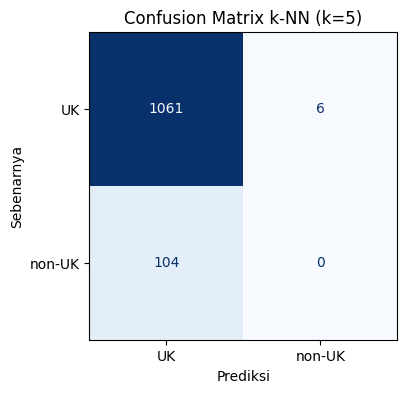

TN (UK → UK)         : 1061
FP (UK → non-UK)     : 6
FN (non-UK → UK)     : 104
TP (non-UK → non-UK) : 0


In [ ]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(cm, display_labels=["UK", "non-UK"]).plot(
    ax=ax, cmap="Blues", values_format="d", colorbar=False
)
ax.set_title("Confusion Matrix k-NN (k=5)")
ax.set_xlabel("Prediksi")
ax.set_ylabel("Sebenarnya")
plt.show()

print(f"TN (UK → UK)         : {tn}")
print(f"FP (UK → non-UK)     : {fp}")
print(f"FN (non-UK → UK)     : {fn}")
print(f"TP (non-UK → non-UK) : {tp}")

## Langkah 9. Metrik evaluasi

Sesuai proposal, evaluasi tidak berhenti di akurasi. Akurasi bisa menyesatkan pada kelas timpang,
jadi dilengkapi precision, recall, F1, dan balanced accuracy (rata-rata recall tiap kelas).

In [ ]:
akurasi   = accuracy_score(y_test, y_pred)
presisi   = precision_score(y_test, y_pred, zero_division=0)
recall    = recall_score(y_test, y_pred, zero_division=0)
f1        = f1_score(y_test, y_pred, zero_division=0)
bal_acc   = balanced_accuracy_score(y_test, y_pred)

hasil = pd.DataFrame({
    "Metrik": ["Akurasi", "Precision (non-UK)", "Recall (non-UK)",
               "F1 (non-UK)", "Balanced accuracy"],
    "Nilai": [akurasi, presisi, recall, f1, bal_acc]
})
hasil["Nilai"] = hasil["Nilai"].round(4)
display(hasil)

print("\nLaporan klasifikasi lengkap:\n")
print(classification_report(y_test, y_pred, target_names=["UK", "non-UK"],
                            digits=4, zero_division=0))

,Metrik,Nilai
0,Akurasi,0.9061
1,Precision (non-UK),0.0000
2,Recall (non-UK),0.0000
3,F1 (non-UK),0.0000
4,Balanced accuracy,0.4972



Laporan klasifikasi lengkap:

              precision    recall  f1-score   support

          UK     0.9107    0.9944    0.9507      1067
      non-UK     0.0000    0.0000    0.0000       104

    accuracy                         0.9061      1171
   macro avg     0.4554    0.4972    0.4754      1171
weighted avg     0.8298    0.9061    0.8663      1171



## Langkah 10. Perbandingan dengan garis dasar 91,15%

Garis dasar dihitung dari seluruh data (91,15%). Karena akurasi model dihitung di data uji,
garis dasar yang adil pada data uji (proporsi UK di data uji) juga ditampilkan.

Garis dasar (seluruh data)        : 91.15%
Garis dasar (di data uji)         : 91.12%
Akurasi k-NN (k=5) di data uji    : 90.61%
Selisih terhadap garis dasar 91,15%: -0.54 poin persen

→ k-NN TIDAK mengalahkan garis dasar.


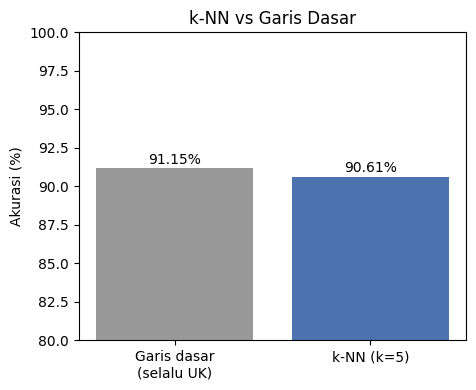

In [ ]:
baseline_uji = (y_test == 0).mean() * 100
akurasi_pct  = akurasi * 100

print(f"Garis dasar (seluruh data)        : {BASELINE:.2f}%")
print(f"Garis dasar (di data uji)         : {baseline_uji:.2f}%")
print(f"Akurasi k-NN (k=5) di data uji    : {akurasi_pct:.2f}%")
print(f"Selisih terhadap garis dasar 91,15%: {akurasi_pct - BASELINE:+.2f} poin persen")

if akurasi_pct > BASELINE:
    print("\n→ k-NN mengalahkan garis dasar.")
else:
    print("\n→ k-NN TIDAK mengalahkan garis dasar.")

plt.figure(figsize=(5, 4))
plt.bar(["Garis dasar\n(selalu UK)", "k-NN (k=5)"],
        [BASELINE, akurasi_pct], color=["#999999", "#4C72B0"])
plt.ylim(80, 100)
plt.ylabel("Akurasi (%)")
plt.title("k-NN vs Garis Dasar")
for i, v in enumerate([BASELINE, akurasi_pct]):
    plt.text(i, v + 0.3, f"{v:.2f}%", ha="center")
plt.show()

## Langkah 11 (tambahan). Validasi silang 5-fold

Satu kali pembagian data bisa kebetulan menguntungkan atau merugikan. Validasi silang berstrata
memberi gambaran yang lebih stabil. Scaler dimasukkan ke dalam *pipeline* agar di-fit ulang
di tiap lipatan (tanpa kebocoran data).

In [ ]:
pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=5)),
])
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

for metrik in ["accuracy", "recall", "f1"]:
    skor = cross_val_score(pipe, X, y, cv=skf, scoring=metrik)
    print(f"{metrik:9s}: rata-rata = {skor.mean():.4f} (± {skor.std():.4f}) | tiap lipatan = {skor.round(3)}")

accuracy : rata-rata = 0.9079 (± 0.0028) | tiap lipatan = [0.906 0.91  0.911 0.909 0.903]
recall   : rata-rata = 0.0213 (± 0.0143) | tiap lipatan = [0.01  0.019 0.019 0.049 0.01 ]
f1       : rata-rata = 0.0389 (± 0.0248) | tiap lipatan = [0.018 0.037 0.037 0.085 0.017]


## Langkah 12. Kesimpulan

*(Isi bagian ini dengan hasil yang muncul saat kamu menjalankan notebook. Contoh di bawah
sesuai hasil dengan `random_state=42` dan split 80:20.)*

- Akurasi k-NN (k=5) sekitar **90,61%**, **di bawah** garis dasar 91,15% (selalu menebak UK).
- Dari 1.171 pelanggan uji (104 di antaranya non-UK), model hanya menebak benar **0** pelanggan
  non-UK (TP = 0, FN = 104). Recall, precision, dan F1 kelas non-UK sama dengan 0.
- Akurasi yang tampak tinggi hampir seluruhnya berasal dari kelas UK (TN = 1.061).
  Model praktis menebak "UK" untuk hampir semua pelanggan.
- Artinya enam fitur RFM-style ini **hampir tidak memisahkan** UK dari non-UK. Ini sejalan dengan
  temuan awal di proposal bahwa fitur-fitur tersebut saling tumpang-tindih antar kelas.
- Hasil ini menjadi titik acuan untuk Anggota 2 (variasi k) dan Anggota 3 (Naive Bayes).
